# Exploration and gold layer

Part 2 of 4 · Previous: [Data and context](01_data_and_context.ipynb) · Next: [Baselines and model](03_baselines_and_model.ipynb)

Small tables from the silver layer show which S.M.A.R.T. attributes each manufacturer reports, how early the
signal appears before a failure, and one drive model whose "failures" were not failures. Each finding fixes a part
of the gold layer: the variables, the horizon H = 15 and the label. Numbers marked † were measured on the large
layers and are not recomputed here.

In [1]:
from backblaze_hdd_failure_prediction.figures import use_style
from backblaze_hdd_failure_prediction.notebooks import exploration_and_gold_layer as nb

use_style()
con = nb.connect()  # DuckDB, with the catalog of drive models loaded

## 1 · Which attributes does each manufacturer report?

Each manufacturer fills in only some S.M.A.R.T. columns. We measure the share of drive-days with a raw value per
manufacturer and attribute (all hard drives, Jul 2023 – Jun 2026; table `attribute_coverage`, written by
`exploration coverage`).

In [2]:
share, always_zero = nb.attribute_coverage(con)
nb.show_attribute_coverage(con, share, always_zero)

46 attributes have a value in some hard drive
Common core (a value on >= 90 % of the drive-days and not always 0, in every manufacturer): [3, 4, 5, 9, 12, 192, 193, 194, 197, 198, 199]
Only Seagate (a value on >= 90 % of its drive-days, under 1 % elsewhere): [187, 188, 190]
Drive-days with a value (%) of 197: {'Seagate': 100.0, 'Toshiba': 93.9, 'WDC': 100.0, 'HGST': 100.0}
Drive-days with a value (%) of 188: {'Seagate': 99.86, 'Toshiba': 0.0, 'WDC': 0.24, 'HGST': 0.0}
Drive models outside Seagate with a value of 188: ['WDC WUH721816ALE6L4']


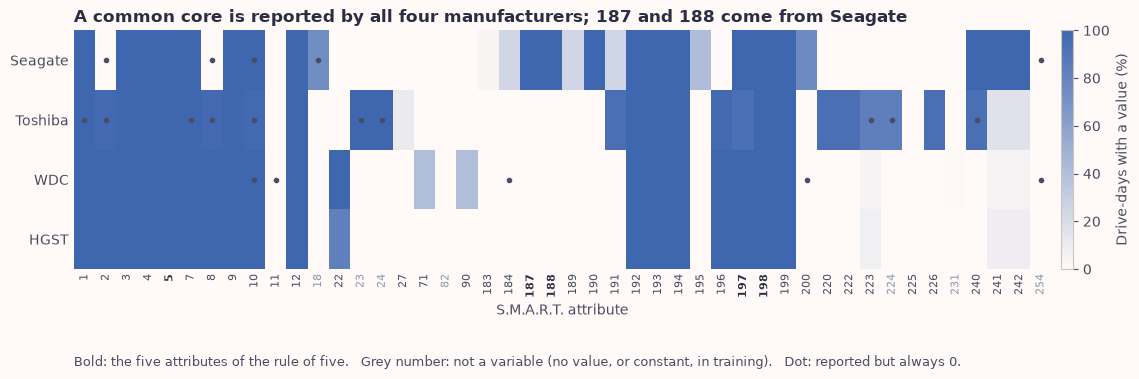

In [3]:
nb.plot_attribute_coverage(con, share, always_zero)

In [4]:
nb.show_attribute_columns(con)

45 attributes have a value in training; constant there: 18 (always 0), 23 (always 0), 24 (always 0), 82 (always 255), 224 (always 0), 254 (always 0)
Variables: 39 raw attributes + the normalised value of 1 and 7 = 41 attribute columns


% of drive-days with raw value > 0 (training),Seagate,Toshiba,WDC,HGST
attribute,,,,
1,99.91,0.0,0.16,0.34
7,99.81,0.0,0.02,0.00


**What we see**

- A common core is filled in, and not always 0, in every manufacturer: 3, 4, 5, 9, 12, 192–194 and 197–199.
- 187 and 188, two of the five rule attributes, come only from Seagate (188 also from one WDC model, 0.24 % of WDC
  drive-days). For the other manufacturers the rule of five is left with 5, 197 and 198.
- Raw 1 and 7 are above 0 almost only in Seagate; 22 (helium level) comes only from WDC and HGST.
- In training, 45 attributes have a value and 6 of them are constant: 39 remain.

> **Decision:** the raw value of those 39 attributes, plus the normalised value of 1 and 7: 41 attribute columns.
> An attribute a manufacturer does not report stays **empty, not 0**.
> **Why:** 0 means "no errors", a healthy value; empty means "not measured", and LightGBM handles empty values on
> their own. Raw values share a unit across manufacturers (normalised ones use each one's scale), but Seagate's raw
> 1 and 7 are composite numbers (median raw 1: 122 million†, also in healthy drives), so we add their normalised
> value. **Discarded:** 0 for unreported attributes.

## 2 · How early does the signal appear, and what is H?

"Will this drive fail?" needs a horizon. The rule was fixed before computing, with training failures only: **H is
the largest value between 10 and 15 days that keeps at least 90 % of the signal visible at 10 days.** A failing
drive *shows signal k days before failing* if one of the five rule attributes is above its reference value (the
first one 60 to 45 days before the failure). Control: the same rise over 45 days in healthy drives (the 1st of each month in training).

In [5]:
curve = nb.signal_curve(con)
nb.show_signal_curve(con, curve)

8,089 training failures in the curve
Signal at 10 days: 62.8 %  ->  90 % bar: 56.5 %
Chosen horizon: H = 15 days (58.2 % with signal); the gold layer uses H = 15
Healthy drives with the same rise: 1.2 %, 54 times less often than at 10 days
H each manufacturer alone would get: {'Seagate': 15, 'Toshiba': 14, 'WDC': 14, 'HGST': 15}


"% of failing drives with signal, k days before",All,Seagate,Toshiba,WDC,HGST
k,,,,,
0,76.5,85.0,58.6,65.0,82.5
7,65.9,74.7,45.9,51.7,74.2
10,62.8,71.7,42.3,46.9,72.0
15,58.2,67.2,37.4,42.0,67.5
30,46.7,55.9,26.0,29.6,56.0


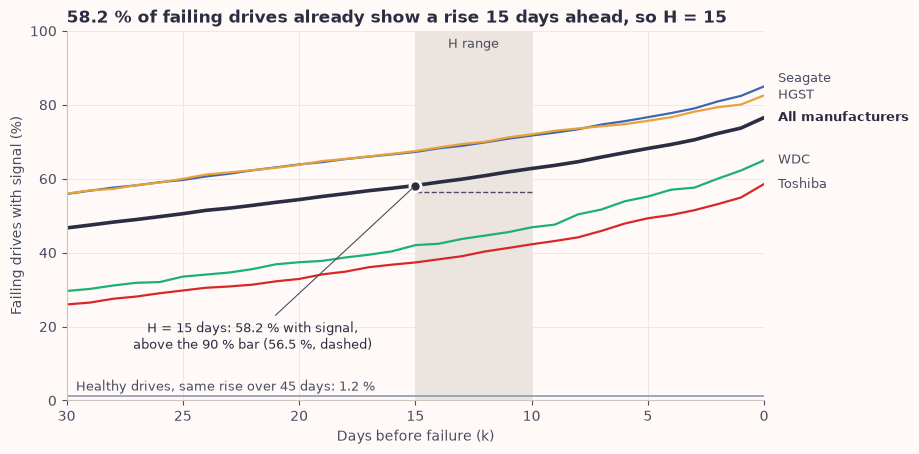

In [6]:
nb.plot_signal_curve(con, curve)

**What we see**

- The signal builds up gradually: 76.5 % of failing drives show it on the failure day, 62.8 % at 10 days, 46.7 % at
  30. About 37 % show no rise 10 days ahead: the ceiling of the rule of five.
- At 15 days, 58.2 % is still above the bar of 56.5 %, so H = 15.
- Toshiba (42.3 % at 10 days) and WDC (46.9 %), without 187 and 188, show less signal than Seagate and HGST (about
  72 %). Alone they would get H = 14, but the rule was fixed on all failures.
- Healthy drives show the same rise in 1.2 % of cases, 54 times less often than failing drives 10 days ahead:
  the signal is real.

> **Decision:** H = 15 days. **Why:** the rule fixed beforehand gives 15; validation and test were not looked at.

> **Decision:** an alert is useful only with at least 2 days of margin. **Why:** copying a 16–22 TB drive takes
> about a day†. Notebook 03 counts the failures detected *with margin* next to all detected ones.

## 3 · The MG08 episode: failures that were not failures

The label trusts Backblaze's `failure` flag. We compute the annualised failure rate (365 × failures / drive-days)
of the Toshiba MG08ACA16TEY per quarter, from the per-quarter counts, and check whether any drive model spiked like
it in training (`episode_candidates`).

In [7]:
mg08 = nb.mg08_by_quarter(con)
nb.show_mg08_episode(con, mg08)

Usual rate in training: 1.85 % a year, with about 5,218 drives
Q3 2025: 215 failures, 16.95 % a year = 9.2 times usual
Q4 2025: 51 failures, 4.14 % a year = 2.2 times usual
Lives treated as retired without failure: 266 (215 + 51)
Real failures expected among them at the usual rate: 23 and 23
Training: 479 quarters of 67 drive models checked, 0 candidates (>= 3 times usual and >= 20 failures); highest ratio with >= 20 failures: 2.5


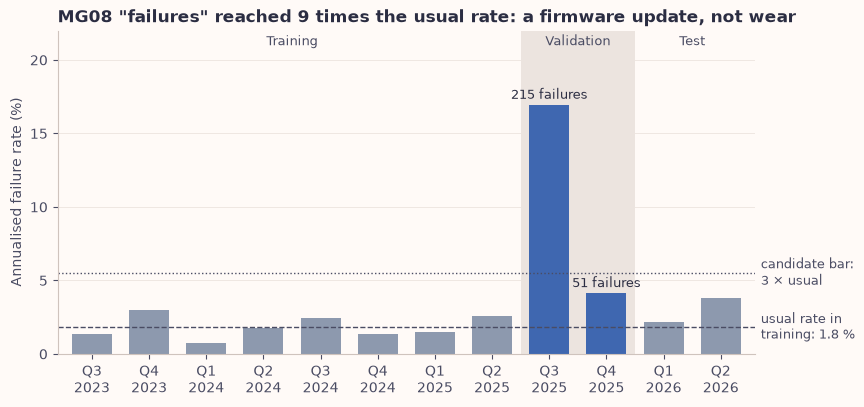

In [8]:
nb.plot_mg08_episode(mg08)

**What we see**

- In Q3 2025 the MG08 "failed" at 16.95 % a year, 9.2 times its usual 1.85 %; in Q4 2025 at 4.14 %, 2.2 times.
- Backblaze's reports explain it: the drives were pulled for a firmware update, not because they broke; Q4 is
  "probably" the same rollout. Only 14 %† of these failures had S.M.A.R.T. signal, against 53 %† usually.
- In training, none of the 479 drive-model quarters is a candidate; the highest ratio among those with at least 20
  failures is 2.5.

> **Decision:** the 266 MG08 failures of Q3–Q4 2025 count as drives retired without failure: their last 15 days
> get no label. **Why:** they were not mechanical failures; kept as failures, they would be misses that never were.
> The cost: about 23 real failures a quarter (the usual rate) are lost too.

> **Decision:** other episodes are searched in training only (≥ 3 times the usual rate, ≥ 20 failures), but
> relabelled only if Backblaze explains there was no mechanical failure (Q4 2025 is below our bar, yet explained).
> **Why:** a spike does not tell a cosmetic failure from a bad batch; dropping spikes by our own criterion would
> remove the hardest failures and flatter the model. **Discarded:** relabelling every candidate.

## 4 · The gold layer: label, variables and time split

One row per drive-day, the same rows as silver, plus the label and the variables; nothing is dropped. First, the
label rule on three toy lives, with the SQL of `gold.py` (k = days to the end of the life).

In [9]:
nb.show_label_examples(con)

k,k = 0,k = 14,k = 15,k = 16,k = 30
drive,,,,,
fails,1,1,1,0,0
leaves without failing,no label,no label,0,0,0
MG08 episode,no label,no label,0,0,0


In [10]:
checks = nb.gold_checks()
nb.show_gold_columns(con, checks)

Gold columns: 141 = 131 variables + 5 location columns (v2) + date, days_to_failure, failure, label, serial_number
Lives: 406,253, of which 155 after a failure; 18 started with their counters reset to 0 (Seagate)


,variables,examples
group,,
drive model,4,"drive_model, manufacturer, is_boot_drive, …"
attribute today,41,"smart_1_raw, smart_2_raw, smart_3_raw, …"
change over 7 days,41,"smart_1_raw_d7, smart_2_raw_d7, smart_3_raw_d7, …"
change over 30 days,41,"smart_1_raw_d30, smart_2_raw_d30, smart_3_raw_..."
life,4,"life, smart_reset, physical_age_hours, …"


In [11]:
per_quarter = nb.labels_by_quarter(checks)
nb.show_labels(per_quarter)

12 quarters: rows equal to silver, no duplicates, no missing keys: True


,drive-days,positives,positive %,negatives per positive,unlabelled,unlabelled %,without any attribute
split,,,,,,,
training,"207,958,144","135,409",0.065,"1,531","522,371",0.251,"48,769"
validation,"60,162,141","26,677",0.044,"2,254","18,215",0.030,175
test,"61,951,368","33,052",0.053,"1,712","5,335,636",8.613,"1,416"
all,"330,071,653","195,138",0.059,"1,660","5,876,222",1.780,"50,360"


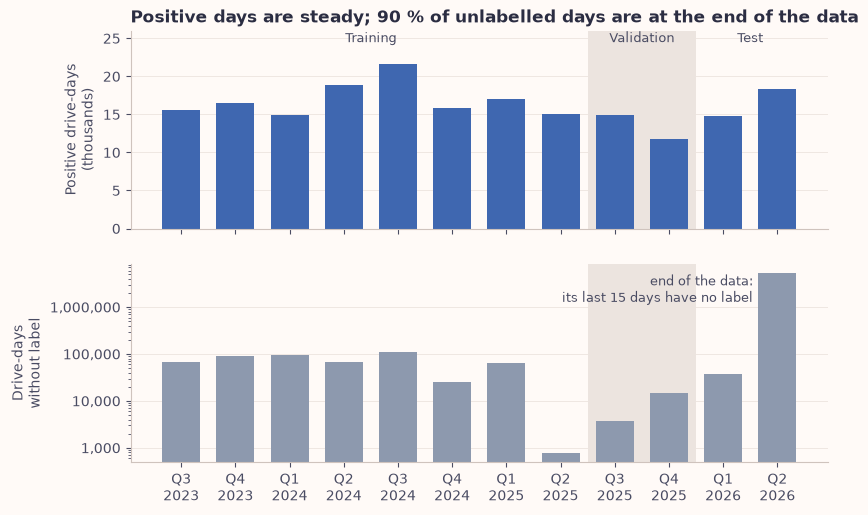

In [12]:
nb.plot_gold_labels(per_quarter)

**What we see**

- 330,071,653 drive-days, as in silver, with no duplicates or missing keys; 141 columns, 17 GB† on disk.
- 195,138 positive drive-days (0.059 %), 11,731 to 21,608 per quarter; in training 135,409, one for every 1,531
  negatives.
- 5,876,222 drive-days have no label, 90 % of them in Q2 2026: the last 15 days of the data.
- 50,360 drive-days (0.015 %) have no attribute at all: the drive could not be read that day.

> **Decision (label):** positive if the life ends in a real failure 0 to 15 days later (16 days, the failure day
> included), 0 otherwise; no label when fewer than 15 days are observed ahead and no real failure is known.
> **Why:** the label answers the model's question (when each drive's pattern starts is the lead time); for those
> days we cannot know whether the drive would have failed.

> **Decision (variables):** for each attribute column, today's value and its change over 7 and 30 days (123
> columns). **Why:** today's value is the accumulated damage, the change says whether it is recent; a tree looks at
> one variable per split, so the change is given ready-made. 30 days catches slow degradation (46.7 % of failures
> had risen 30 days ahead), 7 days sudden changes.

Other variables: drive model, manufacturer, boot-drive flag, capacity (from the drive model), `life`, `smart_reset`
(18 refurbished Seagate lives restarted at 0), physical age and days since reinstall. Unreadable rows stay: dropping
them would break the drive's history, and in training they are positive about 4 times† more often. Location stays
in gold for v2.

> **Decision (time split):** training Jul 2023 – Jun 2025, validation Jul – Dec 2025, test Jan – Jun 2026.
> **Why:** predict the future from the past. Validation is for choosing (tuning, threshold); test stayed untouched
> until the final evaluation (notebook 04).

## Takeaways

- 41 attribute columns keep each manufacturer's own attributes, empty (not 0) where not reported.
- A rule fixed before looking gives **H = 15**: 58.2 % of failing drives already show a rise 15 days ahead.
- The 266 MG08 "failures" of Q3–Q4 2025 were firmware pulls and get no label; other episodes need Backblaze's word.
- Gold: 330 million drive-days, 131 variables, 195,138 positives (0.059 %), split by time.

Next, [notebook 03](03_baselines_and_model.ipynb) decides how to evaluate (per drive life), sets the baselines and
trains LightGBM on a sample of this table.